Task 05: Implement the robust normalization scaling technique

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
dataset_path = "wine-clustering.csv"
df = pd.read_csv(dataset_path)

# Select numerical features
Numerical_features = [
    'Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcanity',
    'Magnesium', 'Total_Phenols', 'Flavanoids',
    'Nonflavanoid_Phenols', 'Proanthocyanins',
    'Color_Intensity', 'Hue', 'OD280', 'Proline'
]

df.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [2]:
# Copy the original dataset
df_Robust = df.copy()

# Calculate the median and IQR
median = df[Numerical_features].median()

Q1 = df[Numerical_features].quantile(0.25)
Q3 = df[Numerical_features].quantile(0.75)

IQR = Q3 - Q1

# Apply Robust Scaling
df_Robust[Numerical_features] = (
    df[Numerical_features] - median
) / IQR

df_Robust.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,0.897338,-0.104730,0.201439,-0.906977,1.526316,0.420804,0.553892,-0.358209,1.050000,0.318792,0.222222,0.924949,0.808050
1,0.114068,-0.057432,-0.633094,-1.930233,0.105263,0.278960,0.374251,-0.477612,-0.392857,-0.104027,0.251852,0.503043,0.777090
2,0.083650,0.334459,0.892086,-0.209302,0.157895,0.420804,0.661677,-0.238806,1.792857,0.332215,0.192593,0.316430,1.055728
3,1.003802,0.057432,0.402878,-0.627907,0.789474,1.413712,0.811377,-0.597015,0.892857,1.043624,-0.311111,0.543611,1.664603
4,0.144487,0.489865,1.467626,0.348837,1.052632,0.420804,0.332335,0.298507,0.378571,-0.124161,0.222222,0.121704,0.126935


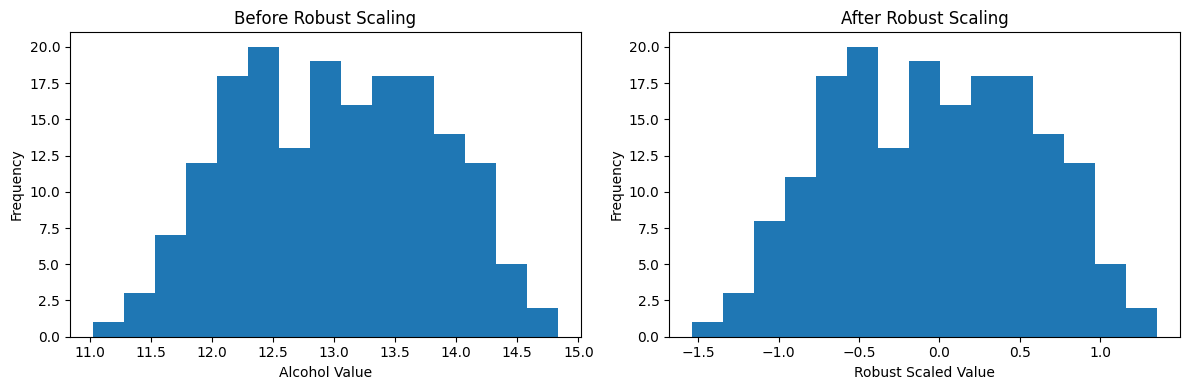

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Original feature
axes[0].hist(df['Alcohol'], bins=15)
axes[0].set_title('Before Robust Scaling')
axes[0].set_xlabel('Alcohol Value')
axes[0].set_ylabel('Frequency')

# Robust-scaled feature
axes[1].hist(df_Robust['Alcohol'], bins=15)
axes[1].set_title('After Robust Scaling')
axes[1].set_xlabel('Robust Scaled Value')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()


In [4]:
from sklearn.preprocessing import RobustScaler

# Create the scaler
scaler = RobustScaler()

# Preserve the original dataset
df_Robust_SK = df.copy()

# Fit and transform the selected features
df_Robust_SK[Numerical_features] = scaler.fit_transform(
    df[Numerical_features]
)

df_Robust_SK.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,0.897338,-0.104730,0.201439,-0.906977,1.526316,0.420804,0.553892,-0.358209,1.050000,0.318792,0.222222,0.924949,0.808050
1,0.114068,-0.057432,-0.633094,-1.930233,0.105263,0.278960,0.374251,-0.477612,-0.392857,-0.104027,0.251852,0.503043,0.777090
2,0.083650,0.334459,0.892086,-0.209302,0.157895,0.420804,0.661677,-0.238806,1.792857,0.332215,0.192593,0.316430,1.055728
3,1.003802,0.057432,0.402878,-0.627907,0.789474,1.413712,0.811377,-0.597015,0.892857,1.043624,-0.311111,0.543611,1.664603
4,0.144487,0.489865,1.467626,0.348837,1.052632,0.420804,0.332335,0.298507,0.378571,-0.124161,0.222222,0.121704,0.126935
